## Middleware

Middleware provides a way to more tightly control what happens inside the agent. Middleware is useful for the following :

Tracking agent behavior with logging, analytics and debugging
Trasforming prompts, tool selection and output formatting
Adding retries, fallback and early termination logic
Applying rate llimits, guardrails and PII detection

In [6]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")


In [2]:
import truststore
truststore.inject_into_ssl()

## Summarization Middleware

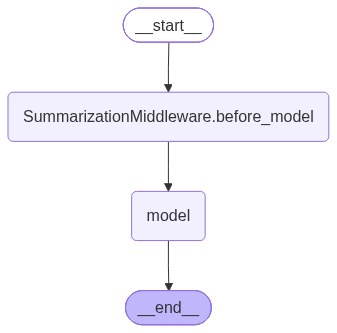

In [3]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, SystemMessage

model = ChatOpenAI(model="gpt-4o",
        api_key=os.getenv("OPENAI_API_KEY"),
        )

middlewareAgent = create_agent(
    model=model,
    debug=True,
    middleware=[SummarizationMiddleware(
        model=model,
        trigger=("messages", 10),
        keep=("messages", 3),
    )],
    checkpointer=InMemorySaver(),
)

### Message based summarization
middlewareAgent



In [4]:
## Run with thread Id
config = {"configurable": {"thread_id": "test1"}}

In [5]:
questions = [
    "What is 2 + 2",
    "What is 10 + 5",
    "What is 9 + 8",
    "What is 2 + 7",
    "What is 100/2",
    "What is 15 - 2",
    "What is 4 *2"
]

for q in questions:
    response = middlewareAgent.invoke({"messages" : [{"role": "user", "content": q}]} , config )
    response["messages"][-1]

[values] {'messages': [HumanMessage(content='What is 2 + 2', additional_kwargs={}, response_metadata={}, id='c424764a-4a32-4e49-8911-447f91b86a14')]}
[updates] {'SummarizationMiddleware.before_model': None}
[updates] {'model': {'messages': [AIMessage(content='2 + 2 equals 4.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 14, 'total_tokens': 22, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_7bfd4ce6e1', 'id': 'chatcmpl-EY9wBLv9qaRerRKkBYVRoeatncPLt', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a13033-c251-7571-9e44-53732cae86b1-0', tool_calls=[]